# Exploratory Data Analysis

This notebook explores the cleaned dataset of generated number sequences and compares patterns between human and computer samples.

## 1. Objective
The analysis below loads the dataset, checks data quality, and compares overall distributions before moving into deeper pattern analysis.

In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# File path
data_dir = Path(r"D:\personal projects\humanVsComputerGeneration\Data")
file_path = data_dir / "clean_combined_dataset.csv"

# Load data
df = pd.read_csv(file_path)

# Define columns
number_cols = [f"number_{i}" for i in range(1, 11)]
label_col = "label"

# Basic overview
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts().rename(index={
    0: "Computer",
    1: "Human"
}))

Dataset shape: (5848, 11)

First 5 rows:


,number_1,number_2,number_3,number_4,number_5,number_6,number_7,number_8,number_9,number_10,label
0,2,5,3,2,4,8,6,8,9,9,0
1,5,2,6,8,1,7,4,3,2,9,1
2,1,9,8,4,5,5,9,5,7,4,0
3,2,4,3,1,8,7,6,5,9,1,1
4,2,7,6,1,9,8,3,5,6,7,1



Missing values:


number_1     0
number_2     0
number_3     0
number_4     0
number_5     0
number_6     0
number_7     0
number_8     0
number_9     0
number_10    0
label        0
dtype: int64


Label distribution:
label
Computer    5000
Human        848
Name: count, dtype: int64


## 2. Data loading and quality checks
This section verifies the dataset shape, previews the first rows, and confirms that there are no missing values. It also reviews the label distribution before deeper exploration.

label
Computer-generated    5000
Human-generated        848
Name: count, dtype: int64


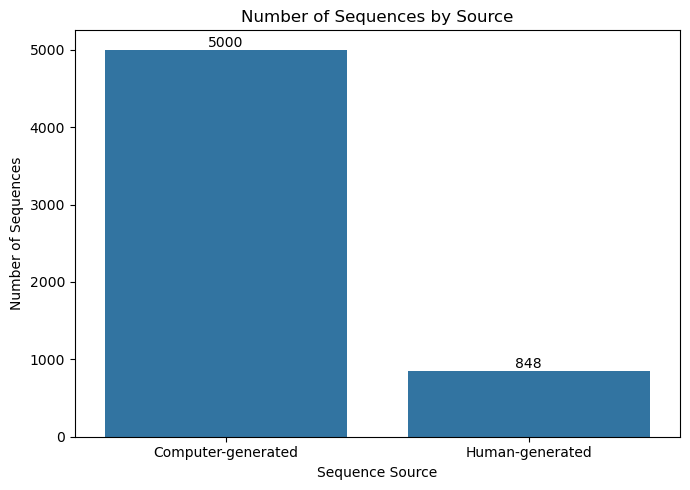

In [22]:

class_counts = df["label"].map({
    0: "Computer-generated",
    1: "Human-generated"
}).value_counts()

print(class_counts)

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

ax.set_title("Number of Sequences by Source")
ax.set_xlabel("Sequence Source")
ax.set_ylabel("Number of Sequences")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

## 3. Feature distributions by position
Here we inspect the distribution of values in each number slot and compare how human-generated and computer-generated sequences differ across positions.

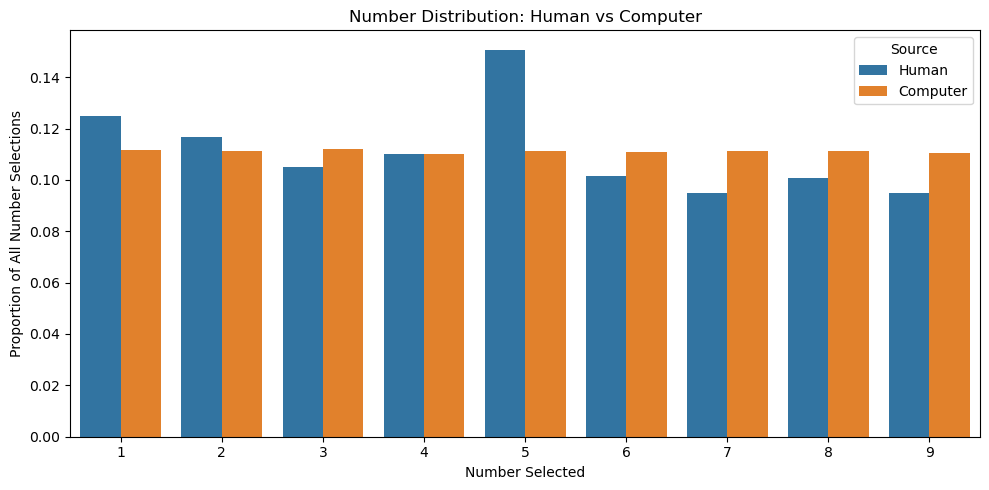

,Number,Human,Computer
0,1,0.1248,0.1116
1,2,0.1169,0.1113
2,3,0.1052,0.1121
3,4,0.1103,0.1099
4,5,0.1507,0.1113
5,6,0.1014,0.1109
6,7,0.0950,0.1114
7,8,0.1007,0.1112
8,9,0.0950,0.1103


In [23]:

# Convert the 10 columns into one long list per group
human_numbers = df.loc[df["label"] == 1, number_cols].to_numpy().ravel()
computer_numbers = df.loc[df["label"] == 0, number_cols].to_numpy().ravel()

# Count occurrences of each number
number_values = range(1, 10)

human_freq = pd.Series(human_numbers).value_counts().reindex(
    number_values, fill_value=0
)
computer_freq = pd.Series(computer_numbers).value_counts().reindex(
    number_values, fill_value=0
)

# Compare relative frequencies rather than raw counts
frequency_df = pd.DataFrame({
    "Number": list(number_values),
    "Human": human_freq.values / len(human_numbers),
    "Computer": computer_freq.values / len(computer_numbers)
})

frequency_long = frequency_df.melt(
    id_vars="Number",
    var_name="Source",
    value_name="Proportion"
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=frequency_long,
    x="Number",
    y="Proportion",
    hue="Source"
)

plt.title("Number Distribution: Human vs Computer")
plt.xlabel("Number Selected")
plt.ylabel("Proportion of All Number Selections")
plt.tight_layout()
plt.show()

display(frequency_df.round(4))

## 4. Relationship between digits and labels
This section looks at how specific digits and position-level patterns relate to the class label, highlighting signals that may distinguish the two generators.

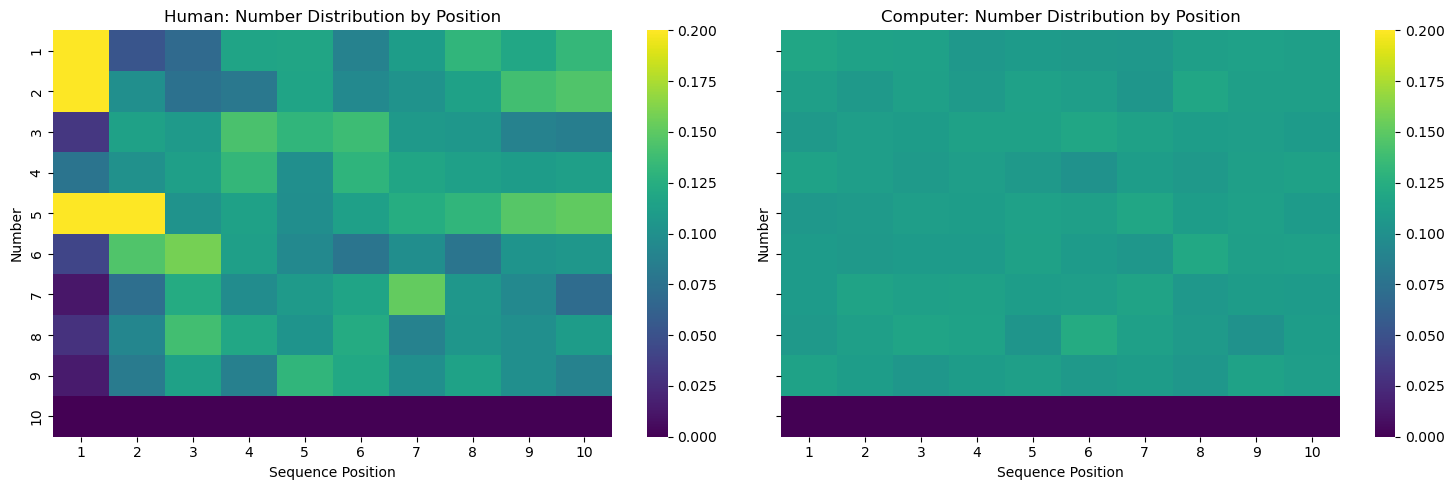

In [24]:

position_rows = []

for label, source in [(1, "Human"), (0, "Computer")]:
    subset = df.loc[df["label"] == label, number_cols]

    for col in number_cols:
        counts = subset[col].value_counts(normalize=True)

        for number in range(1, 11):
            position_rows.append({
                "Source": source,
                "Position": int(col.split("_")[1]),
                "Number": number,
                "Proportion": counts.get(number, 0)
            })

position_df = pd.DataFrame(position_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, source in zip(axes, ["Human", "Computer"]):
    plot_data = position_df[position_df["Source"] == source]

    sns.heatmap(
        plot_data.pivot(
            index="Number",
            columns="Position",
            values="Proportion"
        ),
        cmap="viridis",
        ax=ax,
        vmin=0,
        vmax=0.2
    )

    ax.set_title(f"{source}: Number Distribution by Position")
    ax.set_xlabel("Sequence Position")
    ax.set_ylabel("Number")

plt.tight_layout()
plt.show()

## 5. Sequence-level patterns
This part evaluates the structure of each sequence, including repeated values, ordering, and sequence-level behavior across the dataset.

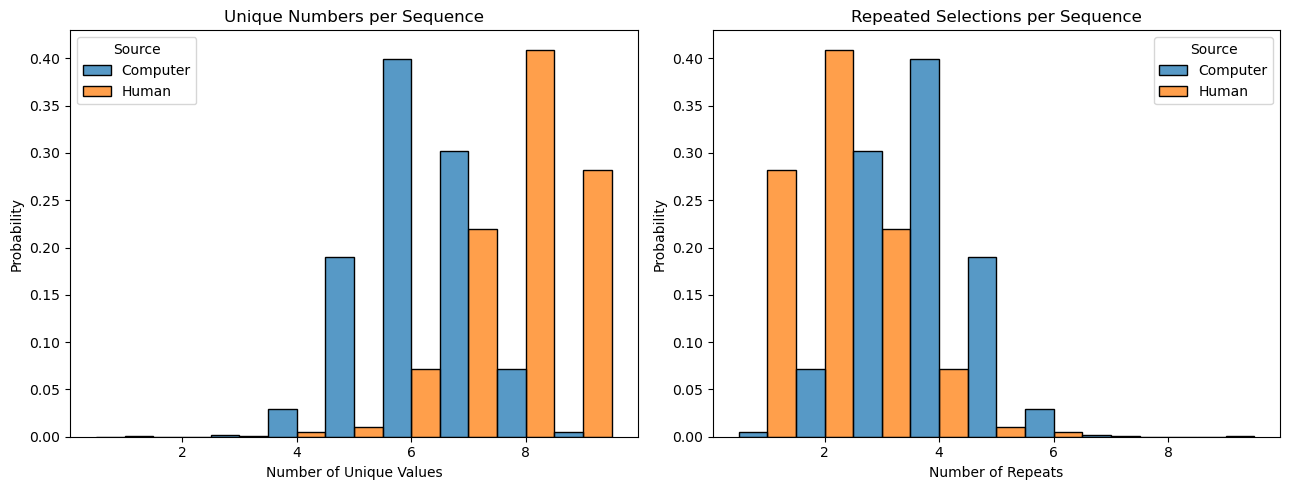

unique_count               repeat_count              
                 mean    std median         mean    std median
Source                                                        
Computer        6.205  0.960    6.0        3.795  0.960    4.0
Human           7.854  1.013    8.0        2.146  1.013    2.0

In [25]:

# Number of unique values in each sequence
df["unique_count"] = df[number_cols].nunique(axis=1)

# Number of repeated selections beyond the first occurrence
df["repeat_count"] = len(number_cols) - df["unique_count"]

df["Source"] = df["label"].map({
    0: "Computer",
    1: "Human"
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=df,
    x="unique_count",
    hue="Source",
    discrete=True,
    stat="probability",
    common_norm=False,
    multiple="dodge",
    ax=axes[0]
)
axes[0].set_title("Unique Numbers per Sequence")
axes[0].set_xlabel("Number of Unique Values")

sns.histplot(
    data=df,
    x="repeat_count",
    hue="Source",
    discrete=True,
    stat="probability",
    common_norm=False,
    multiple="dodge",
    ax=axes[1]
)
axes[1].set_title("Repeated Selections per Sequence")
axes[1].set_xlabel("Number of Repeats")

plt.tight_layout()
plt.show()

display(
    df.groupby("Source")[["unique_count", "repeat_count"]]
      .agg(["mean", "std", "median"])
      .round(3)
)

## 6. Transition and dependency analysis
The next section examines transitions between consecutive digits to determine whether one class exhibits stronger or weaker sequential dependencies.

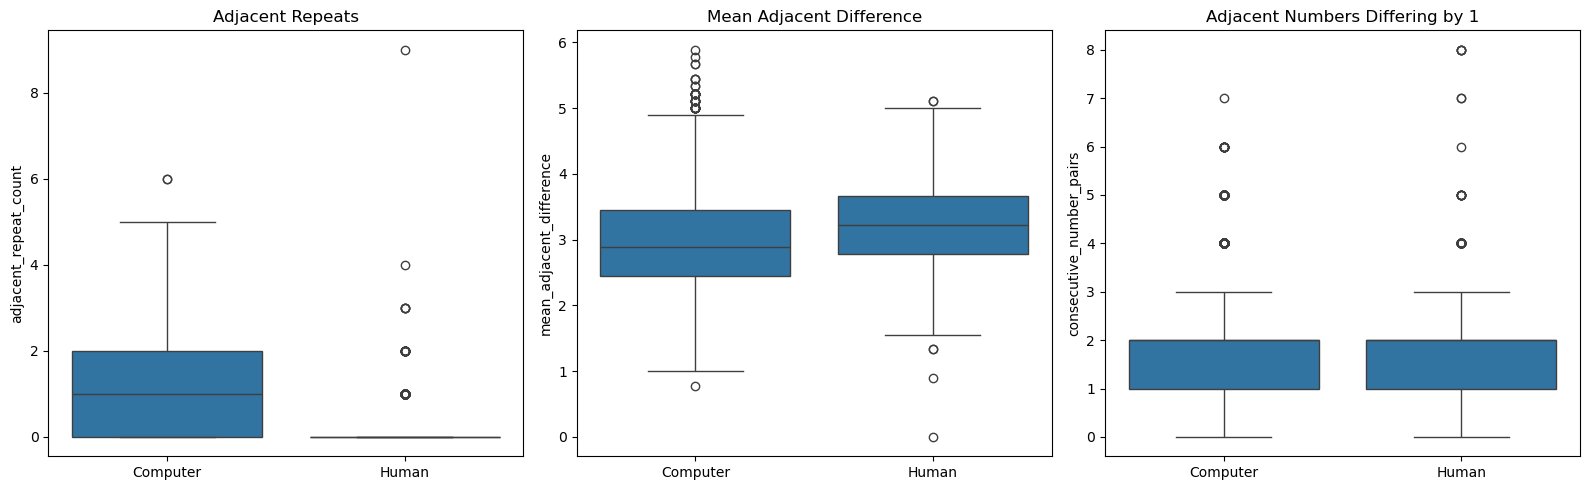

,adjacent_repeat_count,mean_adjacent_difference,consecutive_number_pairs
Source,,,
Computer,1.020,2.965,1.755
Human,0.225,3.239,1.768


In [26]:

X = df[number_cols].to_numpy()

# Adjacent positions: same number twice in a row
df["adjacent_repeat_count"] = (
    X[:, 1:] == X[:, :-1]
).sum(axis=1)

# Absolute differences between adjacent selections
df["mean_adjacent_difference"] = np.abs(
    np.diff(X, axis=1)
).mean(axis=1)

# Count adjacent selections that differ by exactly 1
df["consecutive_number_pairs"] = (
    np.abs(np.diff(X, axis=1)) == 1
).sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, title in zip(
    axes,
    [
        "adjacent_repeat_count",
        "mean_adjacent_difference",
        "consecutive_number_pairs"
    ],
    [
        "Adjacent Repeats",
        "Mean Adjacent Difference",
        "Adjacent Numbers Differing by 1"
    ]
):
    sns.boxplot(data=df, x="Source", y=metric, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

display(
    df.groupby("Source")[
        [
            "adjacent_repeat_count",
            "mean_adjacent_difference",
            "consecutive_number_pairs"
        ]
    ].mean().round(3)
)

## 7. Statistical comparison
This section compares how the distributions differ statistically and identifies whether the observed patterns are meaningful rather than random variation.

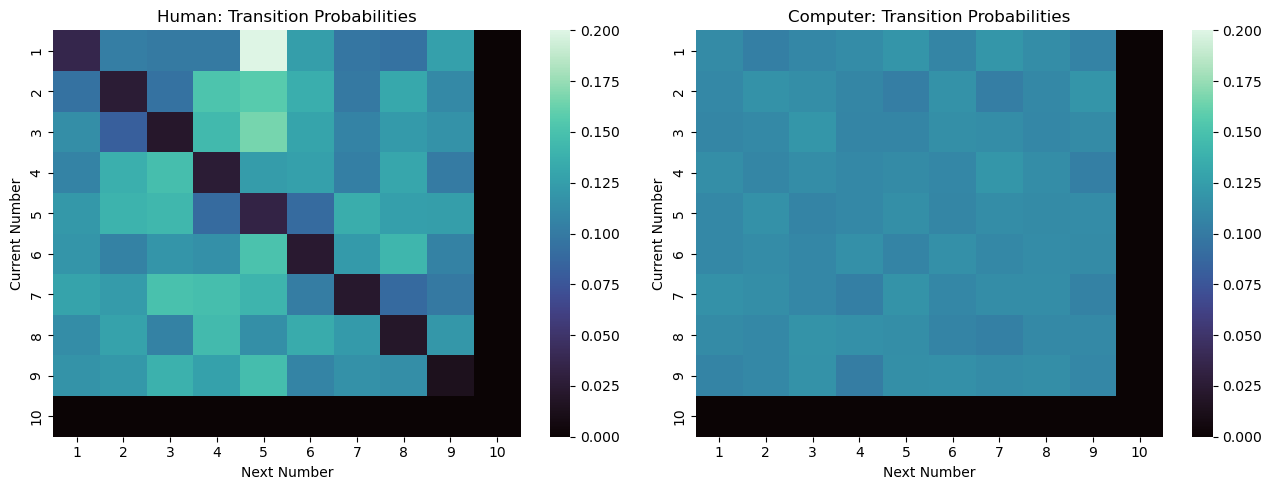

In [27]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, label, source in [
    (axes[0], 1, "Human"),
    (axes[1], 0, "Computer")
]:
    sequences = df.loc[df["label"] == label, number_cols].to_numpy()

    transitions = np.zeros((10, 10), dtype=int)

    for sequence in sequences:
        for current, next_number in zip(sequence[:-1], sequence[1:]):
            transitions[current - 1, next_number - 1] += 1

    # Normalize each row so we compare next-number probabilities
    row_totals = transitions.sum(axis=1, keepdims=True)
    transition_probs = np.divide(
        transitions,
        row_totals,
        out=np.zeros_like(transitions, dtype=float),
        where=row_totals != 0
    )

    sns.heatmap(
        transition_probs,
        ax=ax,
        cmap="mako",
        vmin=0,
        vmax=0.2,
        xticklabels=range(1, 11),
        yticklabels=range(1, 11)
    )

    ax.set_title(f"{source}: Transition Probabilities")
    ax.set_xlabel("Next Number")
    ax.set_ylabel("Current Number")

plt.tight_layout()
plt.show()

## 8. Key takeaways
The final section summarizes the main findings and the most important patterns observed in the dataset.

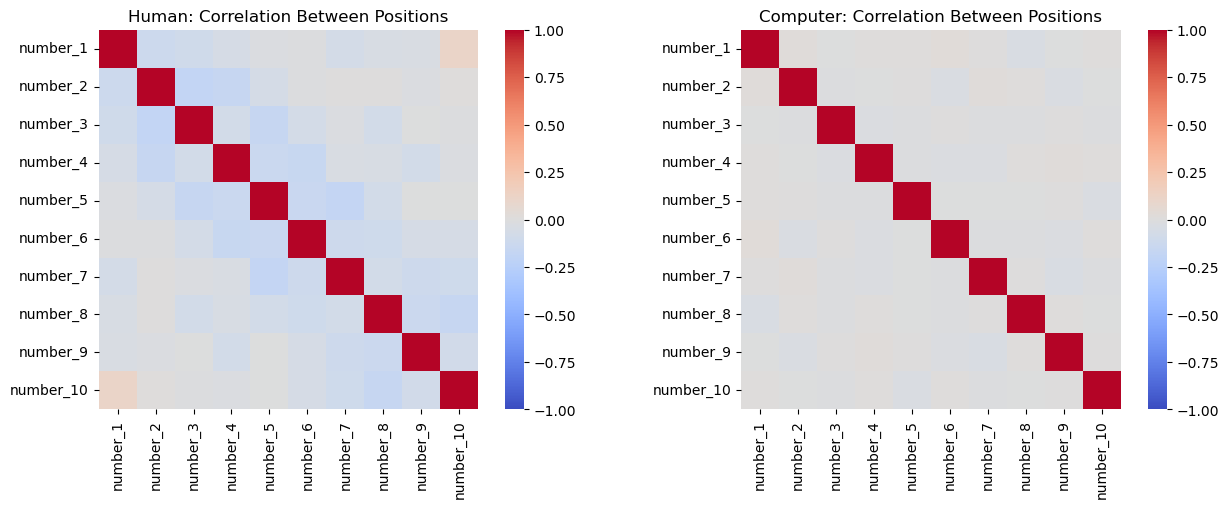

In [28]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, label, source in [
    (axes[0], 1, "Human"),
    (axes[1], 0, "Computer")
]:
    subset = df.loc[df["label"] == label, number_cols]

    sns.heatmap(
        subset.corr(),
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        ax=ax
    )

    ax.set_title(f"{source}: Correlation Between Positions")

plt.tight_layout()
plt.show()